# Machine Learning LAB 2B: LINEAR REGRESSION

Course 2026/27: *F. Chiariotti*

The notebook contains some simple tasks to be performed with **LINEAR REGRESSION MODELS**.

Complete all the **required code sections**.

### IMPORTANT for the exam:

The functions you might be required to implement in the exam will have the same signature and parameters as the ones in the labs

## VR traffic prediction

In this notebook, we will explore the prediction of Virtual Reality (VR) traffic. The data come from the paper:

Lecci, Mattia, _et al._ "An open framework for analyzing and modeling XR network traffic." IEEE Access 9 (2021): 129782-129795.

The VR game Virus Popper was instantiated on a computer through the RiftCat application: the user could then see the virtual content on their phone, which was strapped to their head with a Cardboard viewer. The file virus_popper.csv contains three columns from the traffic capture:
idx    | frame size (B) |  time (s)
0      | 38424          |  0.0
1      | 39801          |  0.01944
...

The game was run at 60 frames per second, with a target rate of 30 Mb/s. The task is then to predict the size of the next frame, given the past N frames. This was explored in another paper:

Chiariotti, Federico, _et al._ "Temporal characterization and prediction of vr traffic: A network slicing use case." IEEE Transactions on Mobile Computing 23.5 (2023): 3890-3908.

---

## Import all the necessary Python libraries

In [1]:
import numpy as np
import pandas as pd
import random as rnd
from matplotlib import pyplot as plt
from sklearn import linear_model, preprocessing
from sklearn.model_selection import train_test_split

np.random.seed(1)

def load_dataset(filename):
    data_train = pd.read_csv(filename)
    data = data_train.iloc[:, 1].values # Get the second column (frame size) as the input
    return data

# Load the dataset
data = load_dataset('data/virus_popper.csv')
data

array([39801, 38983, 38890, ..., 61156, 61630, 58815], shape=(34507,))

## Prepare the data and create training and test sets

In this case, we are learning a time series: let us consider a memory of 2 samples, i.e., use X[n-1] and X[n-2] to predict X[n].

In [2]:
# Normalize the dataset
avg_size = np.mean(data)
norm_data = np.asarray(data) / avg_size

# Compute the splits and prepare the columns
m_training = int(0.75*norm_data.shape[0])

X_training = np.ones([m_training - 2, 3])
X_training[:,1] = norm_data[: m_training - 2]
X_training[:,2] = norm_data[1 : m_training - 1]
Y_training = norm_data[2 : m_training]


X_test = np.ones([norm_data.shape[0] - m_training - 2, 3])
X_test[:,1] = norm_data[m_training : -2]
X_test[:,2] = norm_data[m_training + 1 : -1]
Y_test = norm_data[m_training + 2:]

print(np.shape(X_training), np.shape(Y_training), np.shape(X_test), np.shape(Y_test))

(25878, 3) (25878,) (8625, 3) (8625,)


## Least Squares linear regression

Train and evaluate the LS regressor on the data

In [16]:
# Least squares solution

import scipy as sp

def least_squares(X_matrix: np.ndarray, labels: np.ndarray) -> None:
    ## TODO: Run the LS algorithm without regularization
    # Least squares without regularization: w = (X^T X)^{-1} X^T y = A⁻1 * B
    coeff = np.linalg.inv(X_matrix.T @ X_matrix) @ X_matrix.T @ labels #labels effectively is just Y
    return coeff
    
def evaluate_model(x, y, coeff):
    ## TODO: Return the average MSE for the set over which we evaluate
    predictions = x @ coeff # prediction_t = w0 * 1 + w1 * x_{t-2} + w2 * x_{t-1} all the parameters in a sum, easy to handle
    mse_value = np.mean((predictions - y) ** 2) # mean square error 
    rmse = np.sqrt(mse_value)
    return rmse

print(Y_test[:10]*avg_size)

[50517. 51139. 53503. 76052. 62627. 58668. 57538. 63863. 63454. 62752.]


In [12]:
# Run the LS training and test it on the test data
trained_model = least_squares(X_training, Y_training)
mse = evaluate_model(X_test, Y_test, trained_model)
print('Model coefficients:', trained_model)
print('Root MSE no normalized:', mse * avg_size)
print('Root MSE normalized:', mse)

Model coefficients: [0.36986742 0.20348677 0.42565451]
Root MSE no normalized: 7712.35472153924
Root MSE normalized: 0.12443445155265025


---

## Least Squares with Tikhonov regularization

Perform K-fold cross validation with $\lambda\in\{0, 0.1, 1, 10\}$

In [14]:
# Least squares solution
def regularized_least_squares(X_matrix: np.ndarray, labels: np.ndarray, lambda_par: np.ndarray) -> None:
    ## TODO: Run the LS algorithm with regularization
    # Ridge / Tikhonov: w = (X^T X + 2*lambda*m*I)^{-1} X^T y
    m, d = X_matrix.shape
    A = X_matrix.T @ X_matrix + 2 * lambda_par * m * np.eye(d) #np.eye is the identity matrix, CHECK TIKHONOV LEAST SQUARES LECTURE
    return np.linalg.inv(A) @ X_matrix.T @ labels

def K_fold(X_training: np.ndarray, Y_training: np.ndarray, lambda_vec: np.ndarray, K: int):
    ## TODO: Perform K-fold cross-validation
    m = X_training.shape[0]
    folds = np.array_split(np.arange(m), K)       # K contiguous groups of row indices

    results = np.zeros(len(lambda_vec))           # average validation MSE for each lambda
    for j, lam in enumerate(lambda_vec):
        fold_errors = []
        for k in range(K):
            val_idx = folds[k]
            train_idx = np.concatenate([folds[i] for i in range(K) if i != k])

            w = regularized_least_squares(X_training[train_idx], Y_training[train_idx], lam)
            fold_errors.append(evaluate_model(X_training[val_idx], Y_training[val_idx], w))
        results[j] = np.mean(fold_errors)

    # retrain on the whole training set for every lambda 
    models = [regularized_least_squares(X_training, Y_training, lam) for lam in lambda_vec]

    best_idx = np.argmin(results)
    best_model = models[best_idx]
    best_perf = results[best_idx]
    return best_model, best_perf, models, results

[0.36986742 0.20348677 0.42565451] [0.1487008  0.42555097 0.58962403 0.68257601 0.74213992 0.78352568
 0.81394294 0.83723851 0.85565003 0.87056708 0.88289798 0.89326146
 0.90209347 0.90971009 0.91634599 0.92217912 0.92734682 0.9319568
 0.93609472 0.93982955 0.94321745]


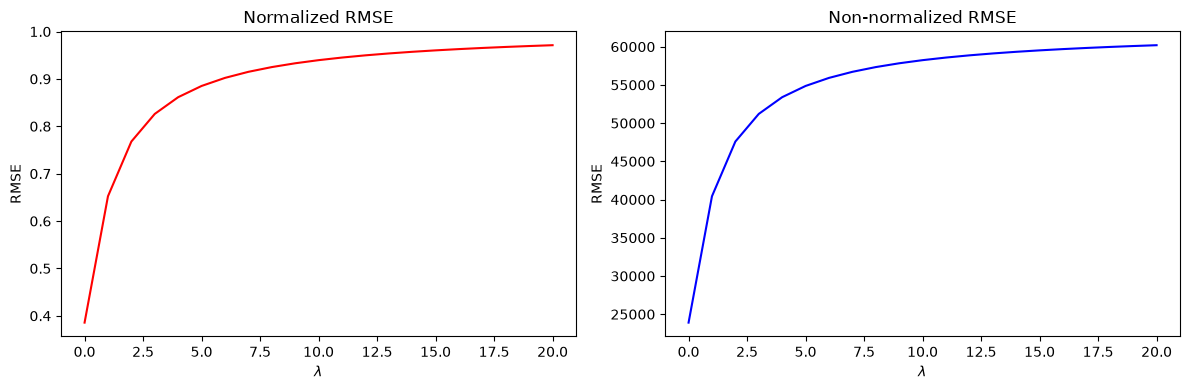

In [15]:
# Run the training with K-fold cross-validation and plot the score
K = 5
lambda_par = range(21)

best_model, best_perf, models, results = K_fold(X_training, Y_training, lambda_par, K)
print(best_model, results)

rmse_norm = np.sqrt(results)          # RMSE in normalized units
rmse_orig = rmse_norm * avg_size      # RMSE in original units

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(lambda_par, rmse_norm, color='red')
ax1.set_title('Normalized RMSE')
ax1.set_xlabel(r'$\lambda$')
ax1.set_ylabel('RMSE')

ax2.plot(lambda_par, rmse_orig, color='blue')
ax2.set_title('Non-normalized RMSE')
ax2.set_xlabel(r'$\lambda$')
ax2.set_ylabel('RMSE')

plt.tight_layout()
plt.show()